![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Unsupervised Learning: Clustering and PCA
*Data Science & Machine Learning - Week 5, Day 3*

## How to use this notebook

Every model so far has learned from examples with an answer attached: churned or not, a price, a diagnosis. That is **supervised** learning. Today there is no answer column. **Unsupervised** learning looks for structure in the features alone:

+ **Clustering** groups similar rows together: customer segments, types of products, groups of patients.
+ **Dimensionality reduction** summarises many features with a few new ones, to visualise data, remove noise or speed up other models.

The slides **3. Unsupervised Methods** in this folder go with the notebook. Every dataset is built into scikit-learn, so there is nothing to download. Run the cells in order.

## Table of contents

- [Setup](#Setup)
- [1. Clustering in two dimensions: k-means](#1.-Clustering-in-two-dimensions:-k-means)
    - [The idea](#The-idea)
    - [Where k-means fails](#Where-k-means-fails)
- [2. A real dataset: wines](#2.-A-real-dataset:-wines)
    - [Scale first](#Scale-first)
    - [How many clusters? The elbow method](#How-many-clusters?-The-elbow-method)
    - [The silhouette score](#The-silhouette-score)
    - [The silhouette plot](#The-silhouette-plot)
- [3. Did the clusters find something real?](#3.-Did-the-clusters-find-something-real?)
- [4. Profiling the clusters](#4.-Profiling-the-clusters)
- [5. Hierarchical clustering](#5.-Hierarchical-clustering)
- [6. DBSCAN: clusters of any shape](#6.-DBSCAN:-clusters-of-any-shape)
    - [Choosing eps: the k-distance plot](#Choosing-eps:-the-k-distance-plot)
    - [DBSCAN on the wines](#DBSCAN-on-the-wines)
- [7. PCA: dimensionality reduction](#7.-PCA:-dimensionality-reduction)
    - [Seeing the clusters](#Seeing-the-clusters)
    - [What do the components mean?](#What-do-the-components-mean?)
    - [PCA before a supervised model](#PCA-before-a-supervised-model)
- [Summary](#Summary)
- [Appendix](#Appendix)
    - [A.1 PCA step by step](#A.1-PCA-step-by-step)
    - [A.2 Association rules](#A.2-Association-rules)
    - [A.3 Anomaly detection](#A.3-Anomaly-detection)

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.datasets import make_blobs, make_moons, load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import IsolationForest

## 1. Clustering in two dimensions: k-means

### The idea

Three groups of points, generated so we know the truth. The algorithm will not see the colours.

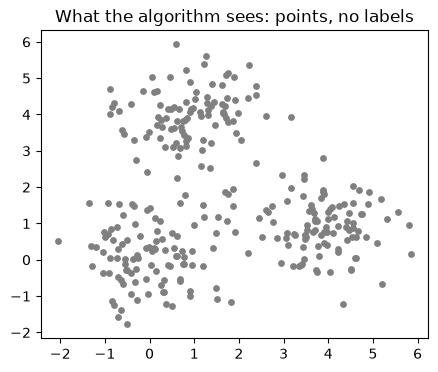

In [2]:
X_blobs, y_blobs = make_blobs(n_samples=300, centers=[[0, 0], [4, 1], [1, 4]], cluster_std=0.8, random_state=0)
plt.figure(figsize=(5, 4))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=15, color="grey")
plt.title("What the algorithm sees: points, no labels")
plt.show()

**K-means** splits the data into *k* clusters, each described by its centre (the **centroid**, the mean of its points). It repeats two steps:

1. **Assign** every point to its nearest centroid.
2. **Update** every centroid to the mean of the points assigned to it.

It stops when the assignments no longer change. Here it starts from three deliberately bad centroids, all in one corner, and we stop it after 1, 2, 3 and 10 rounds to watch it work:

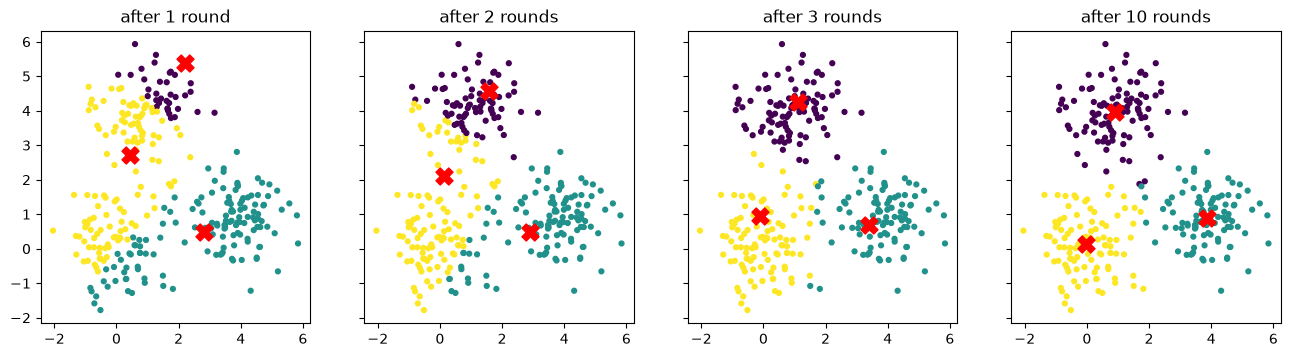

In [3]:
bad_start = np.array([[-2, -2], [-1.5, -2], [-2, -1.5]])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, rounds in zip(axes, [1, 2, 3, 10]):
    km = KMeans(n_clusters=3, init=bad_start, n_init=1, max_iter=rounds).fit(X_blobs)
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=km.labels_, s=12, cmap="viridis")
    ax.scatter(*km.cluster_centers_.T, color="red", marker="X", s=150)
    ax.set_title(f"after {rounds} round{'s' if rounds > 1 else ''}")
plt.show()

By default scikit-learn starts more cleverly (`init="k-means++"` spreads the initial centroids out) and runs the whole algorithm `n_init` times from different starts, keeping the best result.

"Best" means the lowest **inertia**: the sum of squared distances from each point to its centroid. K-means is an algorithm for making inertia small.

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_blobs)
print("Cluster of the first 10 points:", kmeans.labels_[:10])
print("Centroids:\n", kmeans.cluster_centers_.round(2))
print(f"Inertia: {kmeans.inertia_:.1f}")
print("New point (3, 3) goes to cluster", kmeans.predict([[3, 3]])[0])

Cluster of the first 10 points: [1 2 2 1 1 2 0 0 2 1]
Centroids:
 [[ 0.93  3.93]
 [-0.01  0.12]
 [ 3.88  0.89]]
Inertia: 378.1
New point (3, 3) goes to cluster 0


The cluster numbers are arbitrary names: run it with another seed and "cluster 0" may become "cluster 2". Only the grouping matters.

### Where k-means fails

K-means assumes clusters are round blobs of similar size, because every point simply goes to the nearest centre. Two interlocking half-moons break that assumption:

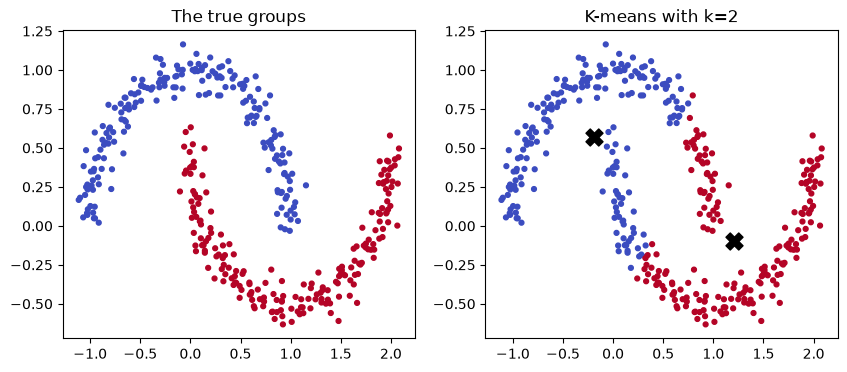

In [5]:
X_moons, y_moons = make_moons(n_samples=400, noise=0.07, random_state=0)
km_moons = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, s=12, cmap="coolwarm")
axes[0].set_title("The true groups")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=km_moons.labels_, s=12, cmap="coolwarm")
axes[1].scatter(*km_moons.cluster_centers_.T, color="black", marker="X", s=150)
axes[1].set_title("K-means with k=2")
plt.show()

K-means cuts the moons with a straight line halfway between its two centroids. Section 5 shows an algorithm that follows their shape.

## 2. A real dataset: wines

The wine dataset has 178 wines from the same region of Italy, described by 13 chemical measurements. They come from three grape cultivars, which we will **hide from the algorithms** and use only at the end, to check whether the clusters found anything real. In a real project you would not have such a column; that is why you would be clustering in the first place.

In [6]:
wine = load_wine(as_frame=True)
X = wine.data
cultivar = wine.target          # kept aside, not used for clustering
print(X.shape)
X.describe().loc[["mean", "std", "min", "max"]].round(2).T

(178, 13)


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


### Scale first

Clustering is all about distances, so the scale of each feature matters even more than for KNN. `proline` is in the hundreds and `hue` around 1: without scaling, the distance between two wines is almost only the difference in proline.

In [7]:
X_scaled = StandardScaler().fit_transform(X)

km_raw = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
km_scaled = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_scaled)

centroids_raw = pd.DataFrame(km_raw.cluster_centers_, columns=X.columns)
print("Unscaled centroids differ mostly in proline:")
print(centroids_raw[["proline", "magnesium", "alcohol", "hue"]].round(2))

Unscaled centroids differ mostly in proline:
   proline  magnesium  alcohol   hue
0   458.23      92.35    12.52  0.94
1  1195.15     105.51    13.80  1.08
2   728.34     103.60    12.93  0.88


We will see in section 3 how much better the scaled version is. From here on, everything uses `X_scaled`.

### How many clusters? The elbow method

Inertia always falls when you add clusters (with one cluster per wine it would be zero), so you cannot just minimise it. The **elbow method** plots inertia against *k* and looks for the point where adding clusters stops paying off.

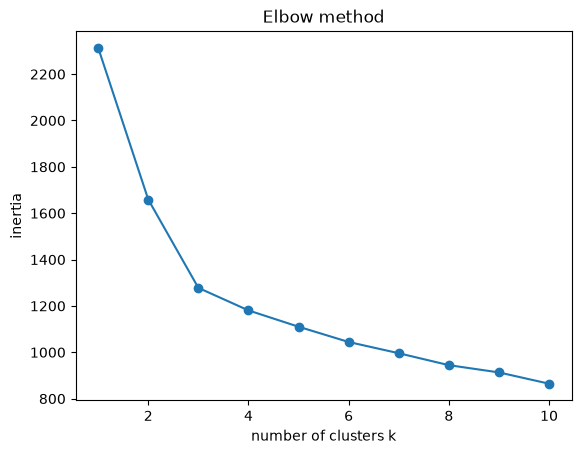

In [8]:
ks = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled).inertia_ for k in ks]
plt.plot(ks, inertias, marker="o")
plt.xlabel("number of clusters k")
plt.ylabel("inertia")
plt.title("Elbow method")
plt.show()

Inertia falls steeply from one to three clusters (from 2,312 to 1,278) and slowly after that, so the elbow is at k = 3.

### The silhouette score

The elbow is often ambiguous, so it helps to have a second opinion. For each point, the **silhouette** compares:

+ *a*: the mean distance to the other points of its own cluster;
+ *b*: the mean distance to the points of the nearest other cluster.

$$s = \frac{b - a}{\max(a, b)}$$

It ranges from −1 to 1. Close to 1: the point sits well inside its cluster. Around 0: it is on the border between two. Negative: it is probably in the wrong cluster. `silhouette_score` is the average over all points; higher is better.

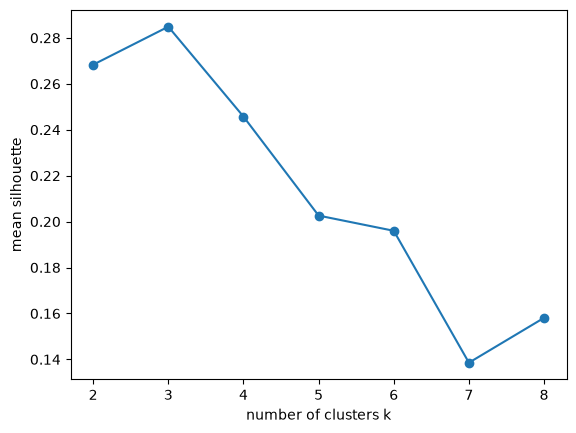

,k,silhouette
0,2,0.268
1,3,0.285
2,4,0.246
3,5,0.203
4,6,0.196
5,7,0.139
6,8,0.158


In [9]:
rows = []
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_scaled)
    rows.append({"k": k, "silhouette": silhouette_score(X_scaled, labels)})
silhouettes = pd.DataFrame(rows)
plt.plot(silhouettes["k"], silhouettes["silhouette"], marker="o")
plt.xlabel("number of clusters k")
plt.ylabel("mean silhouette")
plt.show()
silhouettes.round(3)

The mean silhouette is highest at k = 3 (0.285), which agrees with the elbow. Values around 0.3 are typical of real data: the clusters exist, but they touch at their edges.

### The silhouette plot

The mean hides how individual clusters behave. A silhouette plot draws every point's silhouette, grouped by cluster and sorted. Good clusters are thick and mostly to the right of the mean (the dashed line); a cluster that sits mostly left of it, or has many negative values, is a weak one.

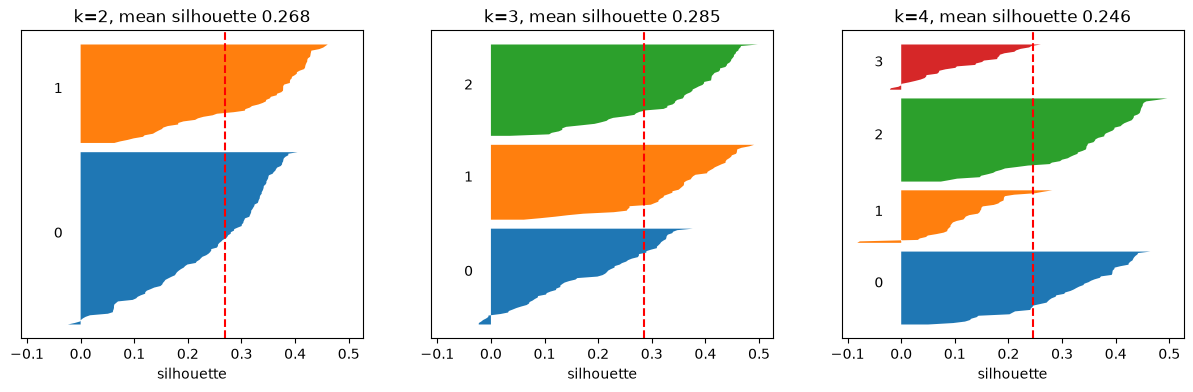

In [10]:
def silhouette_plot(X_data, k, ax):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_data)
    values = silhouette_samples(X_data, labels)
    y_lower = 0
    for c in range(k):
        cluster_values = np.sort(values[labels == c])
        ax.fill_betweenx(np.arange(y_lower, y_lower + len(cluster_values)), 0, cluster_values)
        ax.text(-0.05, y_lower + len(cluster_values) / 2, str(c))
        y_lower += len(cluster_values) + 5
    ax.axvline(values.mean(), color="red", linestyle="--")
    ax.set_title(f"k={k}, mean silhouette {values.mean():.3f}")
    ax.set_yticks([])
    ax.set_xlabel("silhouette")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, k in zip(axes, [2, 3, 4]):
    silhouette_plot(X_scaled, k, ax)
plt.show()

With k = 3, all three clusters are thick and reach well past the mean, with only a handful of negative values. With k = 4, cluster 3 is small and barely reaches the mean, and cluster 1 has negative values: the fourth cluster was carved out of the others rather than found.

Neither method gives *the* right answer. The number of clusters is also a business decision: three segments a marketing team can act on are worth more than seven that look slightly better on a metric.

## 3. Did the clusters find something real?

Now, and only as a check, we bring back the cultivars. A **crosstab** shows how the three clusters line up with the three cultivars:

In [11]:
labels_km = km_scaled.labels_
pd.crosstab(cultivar, labels_km, rownames=["cultivar"], colnames=["cluster"])

cluster,0,1,2
cultivar,,,
0,0,0,59
1,65,3,3
2,0,48,0


Each cultivar falls almost entirely into one cluster: cultivar 0 into cluster 2, cultivar 2 into cluster 1, and cultivar 1 into cluster 0 apart from 6 wines. Without ever seeing the labels, k-means rediscovered the three grape varieties from the chemistry alone, putting 172 of the 178 wines with their own cultivar.

The **adjusted Rand index** (ARI) summarises that agreement in one number: 1 means the clusters match the labels exactly (whatever their numbers), 0 means no better than random. It is only usable when you have true labels, which is rare in practice, but it lets us compare methods today.

In [12]:
print(f"ARI, k-means on unscaled data: {adjusted_rand_score(cultivar, km_raw.labels_):.3f}")
print(f"ARI, k-means on scaled data:   {adjusted_rand_score(cultivar, labels_km):.3f}")
print(f"Silhouette on unscaled data:   {silhouette_score(X, km_raw.labels_):.3f}")
print(f"Silhouette on scaled data:     {silhouette_score(X_scaled, labels_km):.3f}")

ARI, k-means on unscaled data: 0.371
ARI, k-means on scaled data:   0.897
Silhouette on unscaled data:   0.571
Silhouette on scaled data:     0.285


Scaling more than doubles the agreement with the cultivars (ARI 0.371 against 0.897).

The silhouette points the other way: 0.571 unscaled, 0.285 scaled. Unscaled, the distances are almost only proline, a single dimension in which three groups look neatly apart, so the silhouette is high while the clusters ignore the other twelve measurements. Silhouette scores can only be compared on the same data with the same scaling: use them to choose *k*, not to choose the preprocessing.

## 4. Profiling the clusters

A cluster is only useful once you can say what it is. **Profiling** describes each cluster by its features, in the original units, so it can be explained to someone who has never seen the data.

In [13]:
profile = X.assign(cluster=labels_km).groupby("cluster").mean()
profile["size"] = pd.Series(labels_km).value_counts().sort_index()
profile[["size", "alcohol", "proline", "flavanoids", "color_intensity", "hue", "malic_acid"]].round(2)

,size,alcohol,proline,flavanoids,color_intensity,hue,malic_acid
cluster,,,,,,,
0,65,12.25,510.17,2.05,2.97,1.06,1.90
1,51,13.13,619.06,0.82,7.23,0.69,3.31
2,62,13.68,1100.23,3.00,5.45,1.07,2.00


Thirteen columns of means are hard to read. A heatmap of the **scaled** means shows at a glance which features make each cluster different: 0 is the overall average, +1 is one standard deviation above it.

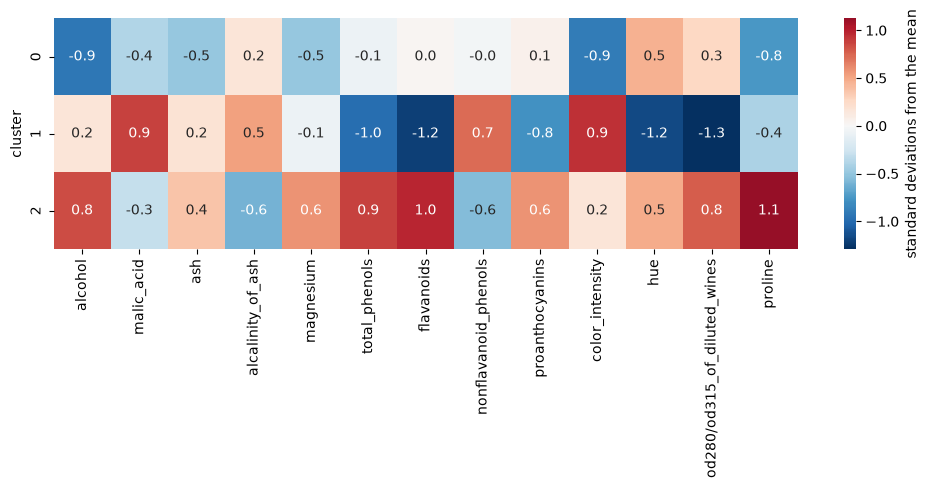

In [14]:
scaled_profile = pd.DataFrame(X_scaled, columns=X.columns).assign(cluster=labels_km).groupby("cluster").mean()
plt.figure(figsize=(12, 3))
sns.heatmap(scaled_profile, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar_kws={"label": "standard deviations from the mean"})
plt.show()

Each cluster now has a description a winemaker could use:

+ **Cluster 0** (65 wines), *light wines*: low alcohol, light colour and low proline.
+ **Cluster 1** (51 wines), *deep-coloured, low in phenols*: intense colour and high malic acid, but low flavanoids, hue and phenols.
+ **Cluster 2** (62 wines), *rich wines*: high proline, flavanoids, phenols and alcohol.

Short names like these are the real deliverable of a segmentation: they are what a business team remembers and acts on.

Box plots of the most distinctive features show whether the clusters overlap or are clearly apart:

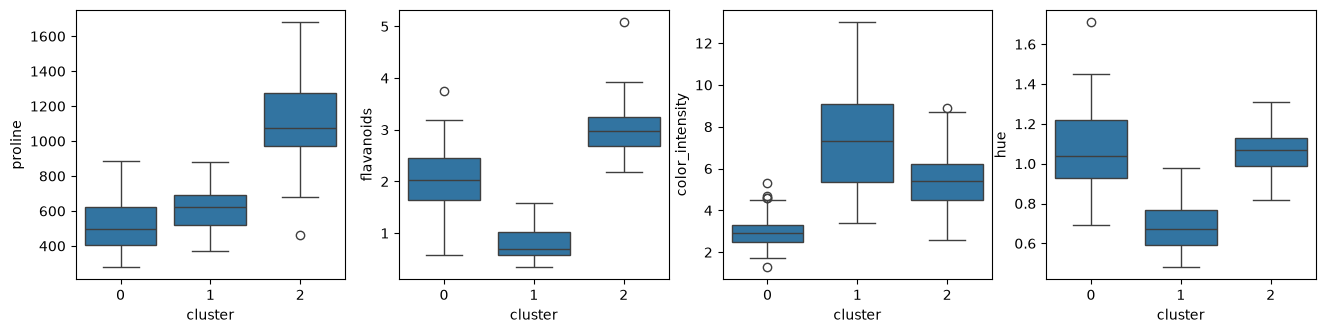

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, feature in zip(axes, ["proline", "flavanoids", "color_intensity", "hue"]):
    sns.boxplot(x=labels_km, y=X[feature], ax=ax)
    ax.set_xlabel("cluster")
plt.show()

## 5. Hierarchical clustering

**Agglomerative** hierarchical clustering starts with every point as its own cluster and repeatedly merges the two closest clusters, until only one is left. It does not need *k* in advance: the whole history of merges is drawn as a tree, the **dendrogram**, and you choose *k* afterwards by cutting it.

How "closest" is measured between two clusters is the **linkage**:

| Linkage | Distance between two clusters | Tends to give |
|---|---|---|
| `ward` (default) | the increase in inertia if they merged | compact clusters of similar size, like k-means |
| `complete` | the largest distance between their points | compact clusters |
| `average` | the mean distance between their points | something in between |
| `single` | the smallest distance between their points | long chains; good for odd shapes, sensitive to noise |

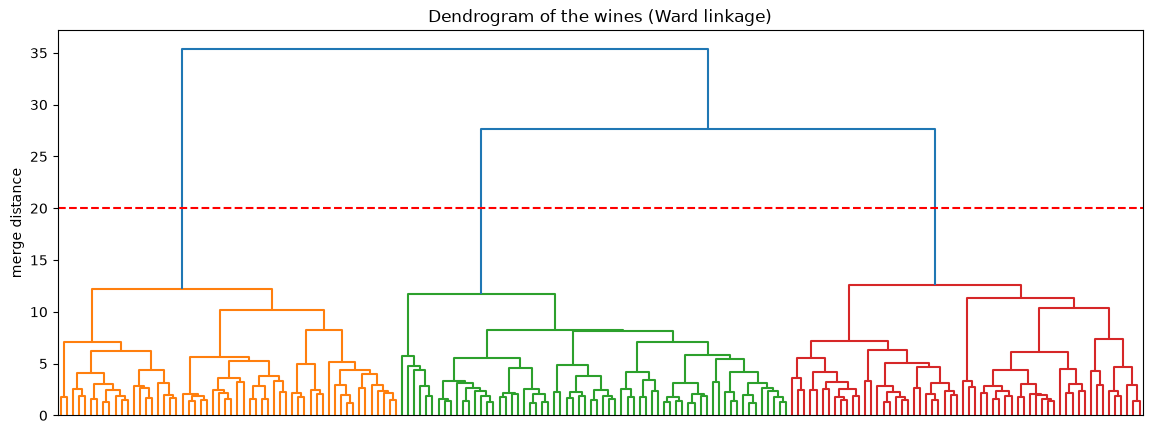

In [16]:
merges = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(merges, no_labels=True, color_threshold=20)
plt.axhline(20, color="red", linestyle="--")
plt.ylabel("merge distance")
plt.title("Dendrogram of the wines (Ward linkage)")
plt.show()

Each vertical line is a cluster; the height where two lines join is how far apart they were when merged. Long vertical lines mean well-separated groups. Cutting at the dashed line, where the lines are longest, gives three clusters.

`fcluster` from SciPy cuts the tree for you, and scikit-learn's `AgglomerativeClustering` does the whole thing in the familiar interface:

In [17]:
labels_tree = fcluster(merges, t=3, criterion="maxclust")         # cut into 3 clusters
print("Cluster sizes from the dendrogram:", np.bincount(labels_tree)[1:])

rows = []
for method in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X_scaled)
    rows.append({"linkage": method,
                 "cluster sizes": sorted(np.bincount(labels), reverse=True),
                 "silhouette": silhouette_score(X_scaled, labels),
                 "ARI": adjusted_rand_score(cultivar, labels)})
pd.DataFrame(rows).round(3)

Cluster sizes from the dendrogram: [56 64 58]


,linkage,cluster sizes,silhouette,ARI
0,ward,"[64, 58, 56]",0.277,0.790
1,complete,"[69, 58, 51]",0.204,0.577
2,average,"[174, 3, 1]",0.158,-0.005
3,single,"[174, 3, 1]",0.183,-0.007


Cutting the Ward dendrogram and `AgglomerativeClustering` give the same three clusters. Ward is close to k-means (ARI 0.790), and complete linkage is weaker. Average and single linkage put 174 of the 178 wines in one cluster and leave a few outliers as tiny clusters of 3 and 1: with no clear gap between the groups, they chain everything together. Ward is the default for good reason.

| | K-means | Hierarchical |
|---|---|---|
| Choose *k* | before | after, by cutting the dendrogram |
| Result for a new point | `predict` assigns it | no `predict`; refit |
| Size of data | scales to millions of rows | slow beyond ~10,000 rows (it compares every pair) |
| Extra output | centroids | the dendrogram |

## 6. DBSCAN: clusters of any shape

**DBSCAN** (*density-based spatial clustering of applications with noise*) defines a cluster as a dense region of points. It has two settings:

+ `eps`: the radius of a point's neighbourhood.
+ `min_samples`: how many points (itself included) must fall in that neighbourhood for the point to be a **core point**.

Core points that are within `eps` of each other form a cluster, together with the points they reach. Points that belong to no dense region are labelled **noise**, cluster `-1`. DBSCAN finds the number of clusters by itself, and it can follow any shape.

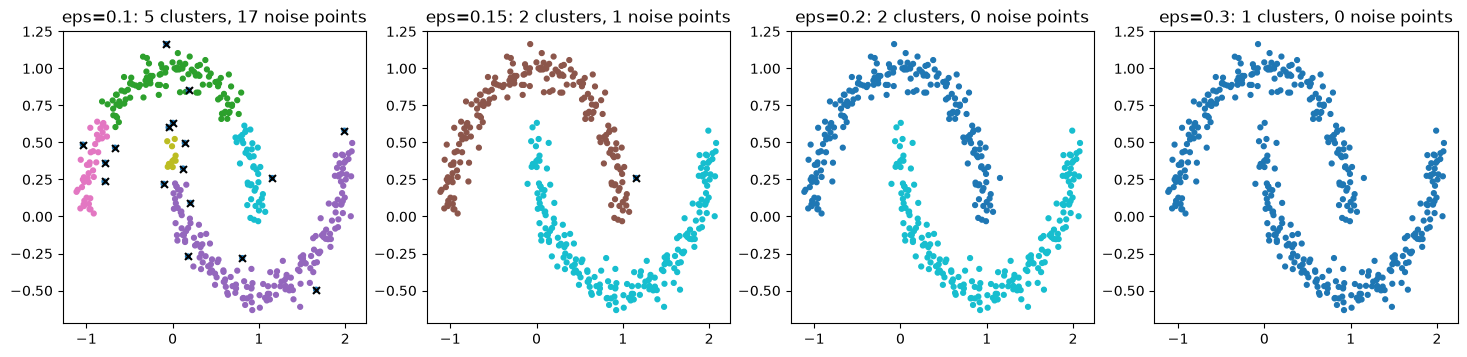

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, eps in zip(axes, [0.1, 0.15, 0.2, 0.3]):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_moons)
    n_clusters = len(set(labels) - {-1})
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, s=12, cmap="tab10")
    ax.scatter(*X_moons[labels == -1].T, color="black", marker="x", s=25)
    ax.set_title(f"eps={eps}: {n_clusters} clusters, {np.sum(labels == -1)} noise points")
plt.show()

With `eps=0.1` the neighbourhoods are too small: the moons break into fragments and 17 points become noise. At 0.15 and 0.2, DBSCAN finds the two moons exactly, which k-means could not do. At 0.3 the neighbourhoods are so large that the two moons join into one cluster.

### Choosing eps: the k-distance plot

For every point, compute the distance to its `min_samples`-th nearest neighbour and sort those distances. Points inside clusters have small distances; noise points have large ones. A good `eps` is where the curve bends upwards.

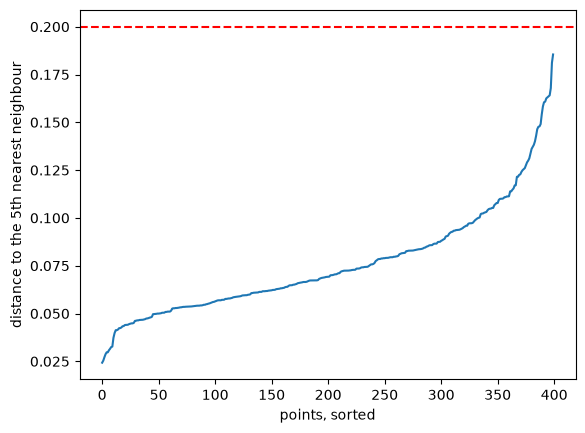

In [19]:
distances, _ = NearestNeighbors(n_neighbors=5).fit(X_moons).kneighbors(X_moons)
plt.plot(np.sort(distances[:, -1]))
plt.axhline(0.2, color="red", linestyle="--")
plt.xlabel("points, sorted")
plt.ylabel("distance to the 5th nearest neighbour")
plt.show()

The curve stays low for most points and bends upwards at the end, around 0.15. A value just above the bend, between about 0.15 and 0.2, separates the two moons.

`min_samples` is usually set from experience: at least the number of features plus one, and higher for noisier data.

### DBSCAN on the wines

Density is harder to find in 13 dimensions, because distances between points become more alike as dimensions grow.

In [20]:
for eps in [1.8, 2.2, 2.6]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    print(f"eps={eps}: {len(set(labels) - {-1})} clusters, {np.sum(labels == -1)} of 178 wines labelled noise")

eps=1.8: 7 clusters, 118 of 178 wines labelled noise
eps=2.2: 2 clusters, 55 of 178 wines labelled noise
eps=2.6: 1 clusters, 20 of 178 wines labelled noise


No `eps` works well. Small values call most wines noise, middle values find two clusters and leave 55 wines out, and larger values merge everything. In 13 dimensions the three wine groups touch each other, with no low-density gap for DBSCAN to find. Here k-means and Ward are the better tools; DBSCAN is for dense groups separated by empty space, such as locations on a map, and for spotting outliers.

## 7. PCA: dimensionality reduction

We cannot plot 13 dimensions. **Principal component analysis** (PCA) finds new axes, the **principal components**, that summarise the data:

+ The first component is the direction in which the data varies most.
+ The second is the direction of most remaining variation, at a right angle to the first, and so on.
+ Each component is a weighted mix of the original features.

Keeping the first few components keeps most of the information in far fewer columns. Like clustering, PCA depends on scale, so it always comes after a scaler unless the features share a unit.

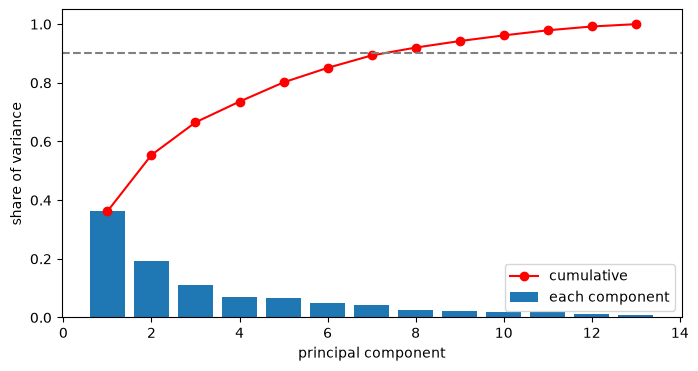

,component,explained variance,cumulative
0,1,0.362,0.362
1,2,0.192,0.554
2,3,0.111,0.665
3,4,0.071,0.736
4,5,0.066,0.802
5,6,0.049,0.851


In [21]:
pca = PCA().fit(X_scaled)
explained = pd.DataFrame({"component": range(1, 14),
                          "explained variance": pca.explained_variance_ratio_,
                          "cumulative": pca.explained_variance_ratio_.cumsum()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(explained["component"], explained["explained variance"], label="each component")
ax.plot(explained["component"], explained["cumulative"], marker="o", color="red", label="cumulative")
ax.axhline(0.9, color="grey", linestyle="--")
ax.set_xlabel("principal component")
ax.set_ylabel("share of variance")
ax.legend()
plt.show()
explained.head(6).round(3)

The first component explains 36% of the variance and the first two together 55%. It takes 8 of the 13 components to pass 90% (the dashed line).

### Seeing the clusters

Projecting the wines onto the first two components gives a map of the data. Coloured by the k-means clusters from section 2:

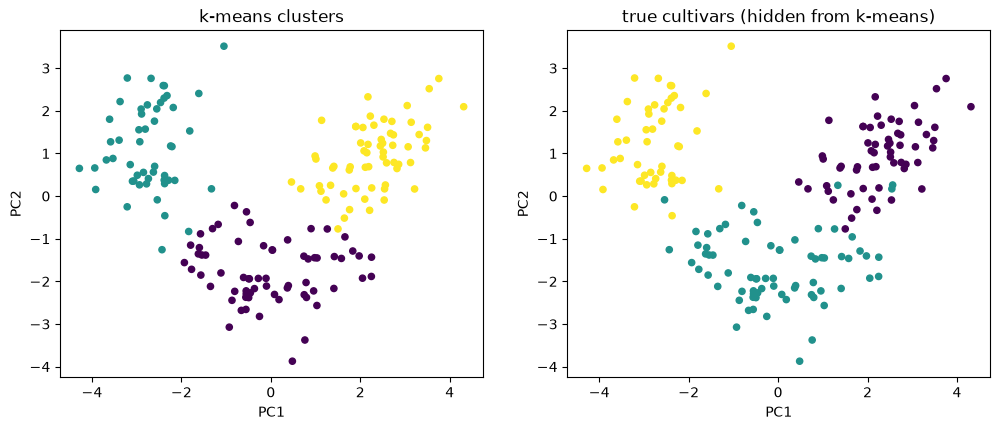

In [22]:
X_2d = PCA(n_components=2).fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=labels_km, cmap="viridis", s=20)
axes[0].set_title("k-means clusters")
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=cultivar, cmap="viridis", s=20)
axes[1].set_title("true cultivars (hidden from k-means)")
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.show()

The three groups are clearly visible in two dimensions, and the clusters and the cultivars look almost the same. The colours differ between the two plots only because cluster numbers are arbitrary names. This is the most common use of PCA in practice: a 2D picture of high-dimensional data and of a clustering.

### What do the components mean?

`components_` holds the weight, or **loading**, of each original feature in each component. Large weights, positive or negative, tell you what a component measures.

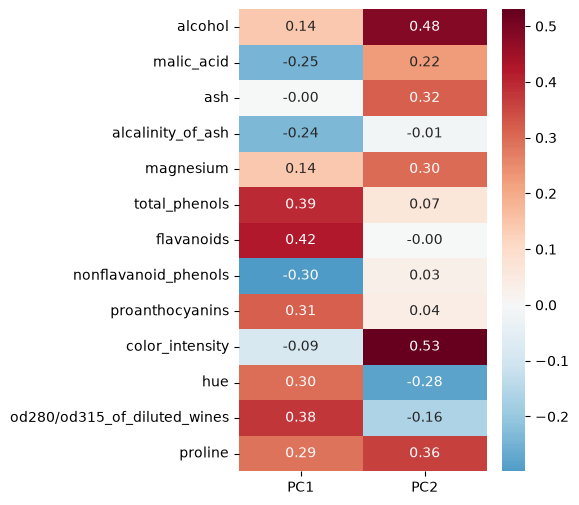

In [23]:
loadings = pd.DataFrame(PCA(n_components=2).fit(X_scaled).components_.T, index=X.columns, columns=["PC1", "PC2"])
plt.figure(figsize=(4, 6))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f")
plt.show()

+ **PC1** is mostly about phenols: flavanoids, total phenols, `od280/od315` and proanthocyanins weigh positively, nonflavanoid phenols negatively.
+ **PC2** is mostly colour intensity, alcohol and proline.

That matches the profiles in section 4: the rich wines (cluster 2) sit on the right, high on PC1; the deep-coloured, low-phenol wines (cluster 1) on the left; the light, low-alcohol wines (cluster 0) at the bottom, low on PC2.

### PCA before a supervised model

PCA can also shrink the input of a supervised model. Passing a number between 0 and 1 as `n_components` keeps as many components as needed to explain that share of the variance. On the 8×8 handwritten digits (64 pixel features):

In [24]:
X_dig, y_dig = load_digits(return_X_y=True)
for n in [None, 0.95, 0.80, 10]:
    steps = [StandardScaler()] + ([PCA(n_components=n)] if n else []) + [LogisticRegression(max_iter=2000)]
    pipe = make_pipeline(*steps)
    acc = cross_val_score(pipe, X_dig, y_dig, cv=5).mean()
    kept = pipe.fit(X_dig, y_dig).named_steps["pca"].n_components_ if n else 64
    print(f"n_components={str(n):<5} features used: {kept:>2}   cross-validated accuracy {acc:.3f}")

n_components=None  features used: 64   cross-validated accuracy 0.920
n_components=0.95  features used: 40   cross-validated accuracy 0.912
n_components=0.8   features used: 21   cross-validated accuracy 0.900


n_components=10    features used: 10   cross-validated accuracy 0.840


Keeping 95% of the variance needs 40 of the 64 features and costs less than a point of accuracy (0.920 against 0.912); keeping only 10 components costs 8 points. On a dataset this small PCA mainly saves time; it pays off when there are many redundant features. PCA goes inside the pipeline, after the scaler, so that it is fitted on the training folds only.

PCA only finds straight-line combinations of features. For pictures of complex data, methods such as t-SNE and UMAP draw better 2D maps, but their axes have no meaning and they cannot transform new data the same way, so they are for visualisation only.

## Summary

| Method | You choose | Finds | Good for | Watch out |
|---|---|---|---|---|
| K-means | *k* | round clusters of similar size | large data, segmentation | scale first; one cluster per centroid, even for odd shapes |
| Hierarchical | linkage, then where to cut | a tree of nested clusters | small data, seeing the structure | slow on large data; no `predict` |
| DBSCAN | `eps`, `min_samples` | dense regions of any shape, plus noise | odd shapes, outliers | hard to tune in many dimensions |
| PCA | number of components | new uncorrelated axes, by variance | visualising, compressing features | linear only; scale first |

+ **Scale** before any distance-based method.
+ Choose *k* with the **elbow** and the **silhouette**, then check that the clusters make sense to the business.
+ A cluster is only useful once it is **profiled**: describe it in the original units and give it a name.
+ With true labels (rare), the **adjusted Rand index** measures how well clusters match them.

## Appendix

### A.1 PCA step by step

PCA is a short piece of linear algebra: the principal components are the **eigenvectors** of the covariance matrix of the scaled data, and each **eigenvalue** is the variance along its component.

In [25]:
cov = np.cov(X_scaled, rowvar=False)                       # 13 x 13 covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(cov)            # eigh: for symmetric matrices
order = np.argsort(eigenvalues)[::-1]                      # largest variance first
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

print("Share of variance, by hand:  ", (eigenvalues / eigenvalues.sum())[:4].round(3))
print("Share of variance, sklearn:  ", pca.explained_variance_ratio_[:4].round(3))

projected = X_scaled @ eigenvectors[:, :2]                 # project onto the first two components
same = np.allclose(np.abs(projected), np.abs(X_2d))
print("Same projection as sklearn (up to the sign of each axis):", same)

Share of variance, by hand:   [0.362 0.192 0.111 0.071]
Share of variance, sklearn:   [0.362 0.192 0.111 0.071]
Same projection as sklearn (up to the sign of each axis): True


The sign of an eigenvector is arbitrary, which is why a component can come out flipped between two tools.

### A.2 Association rules

Association rules find items that appear together, as in "customers who buy bread often buy butter". For a rule *A → B* over a list of transactions:

+ **support**: share of transactions containing both A and B;
+ **confidence**: share of transactions with A that also contain B, an estimate of P(B | A);
+ **lift**: confidence divided by the support of B. Above 1, A makes B more likely than usual; around 1, they are unrelated.

On a toy shop with ten baskets, computed with pandas. Rules seen in fewer than 20% of the baskets are dropped, the usual minimum-support filter:

In [26]:
baskets = [["bread", "butter", "jam"], ["bread", "butter"], ["bread", "butter", "milk"], ["bread", "jam"],
           ["coffee", "milk"], ["coffee", "milk", "bread"], ["coffee", "milk"], ["milk"],
           ["bread", "butter", "coffee"], ["coffee", "biscuits"]]
items = sorted({item for basket in baskets for item in basket})
onehot = pd.DataFrame([[item in basket for item in items] for basket in baskets], columns=items)

rules = []
for a in items:
    for b in items:
        if a == b:
            continue
        support = (onehot[a] & onehot[b]).mean()
        if support < 0.2:
            continue
        confidence = support / onehot[a].mean()
        rules.append({"rule": f"{a} -> {b}", "support": support, "confidence": confidence,
                      "lift": confidence / onehot[b].mean()})
pd.DataFrame(rules).sort_values("lift", ascending=False).round(2)

,rule,support,confidence,lift
0,bread -> butter,0.4,0.67,1.67
2,bread -> jam,0.2,0.33,1.67
4,butter -> bread,0.4,1.00,1.67
7,jam -> bread,0.2,1.00,1.67
6,coffee -> milk,0.3,0.60,1.20
9,milk -> coffee,0.3,0.60,1.20
1,bread -> coffee,0.2,0.33,0.67
3,bread -> milk,0.2,0.33,0.67
5,coffee -> bread,0.2,0.40,0.67
8,milk -> bread,0.2,0.40,0.67


Bread and butter go together (lift 1.67: a customer with butter is 1.67 times as likely as average to have bread), and so do coffee and milk (1.2). Bread with coffee or milk has a lift below 1: those customers are *less* likely than average to buy both. The biscuits rule disappeared because a single basket is not enough evidence.

On real data with thousands of products, checking every pair is too slow; the **Apriori** algorithm only looks at combinations whose parts are already frequent. The `mlxtend` library implements it (`pip install mlxtend`, then `apriori` and `association_rules`).

### A.3 Anomaly detection

Unsupervised methods can also flag unusual rows: fraud, faulty sensors, data entry errors. DBSCAN's noise points are one way. **Isolation Forest** is another: it builds random trees that split on random features at random thresholds. Unusual points are isolated after very few splits, so the shorter a point's average path, the more anomalous it is. `contamination` is the share of anomalies you expect.

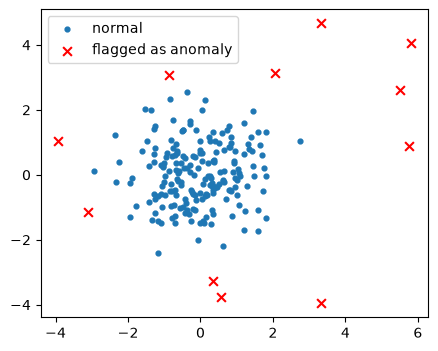

11 points flagged; of the 10 planted ones, 8 were caught


In [27]:
rng = np.random.default_rng(0)
normal_points = rng.normal(0, 1, size=(200, 2))
odd_points = rng.uniform(-6, 6, size=(10, 2))
X_anom = np.vstack([normal_points, odd_points])

iso = IsolationForest(contamination=0.05, random_state=0).fit(X_anom)
flags = iso.predict(X_anom)                     # -1 = anomaly, 1 = normal
plt.figure(figsize=(5, 4))
plt.scatter(*X_anom[flags == 1].T, s=12, label="normal")
plt.scatter(*X_anom[flags == -1].T, color="red", s=40, marker="x", label="flagged as anomaly")
plt.legend()
plt.show()
print(f"{np.sum(flags == -1)} points flagged; of the 10 planted ones, {np.sum(flags[200:] == -1)} were caught")

The two planted points it missed landed inside the normal cloud, so they are not unusual and missing them is right. The three normal points it flagged sit in the far tails of the cloud: with `contamination=0.05` the model must flag about 5% of the rows, whatever they are.

`sklearn.svm.OneClassSVM` and `sklearn.neighbors.LocalOutlierFactor` are two other options with the same `fit` / `predict` interface.